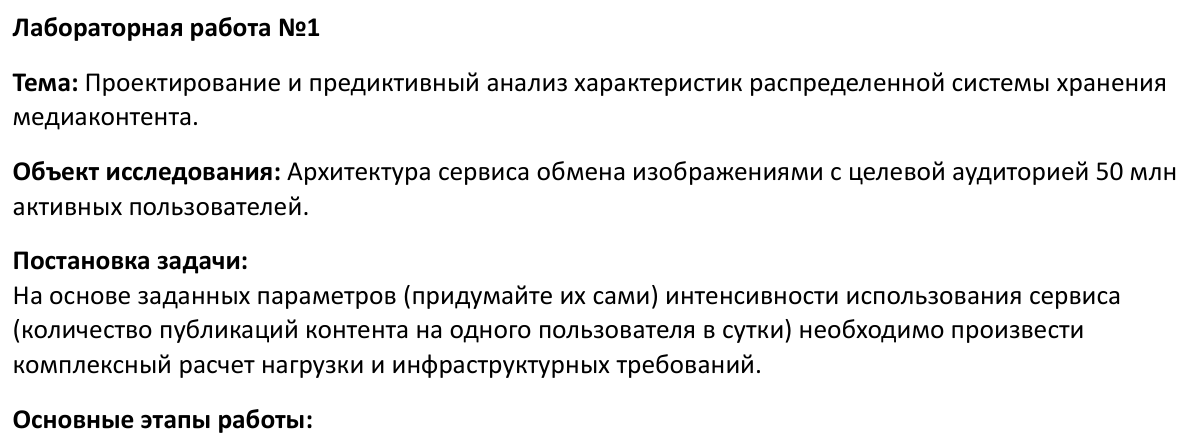

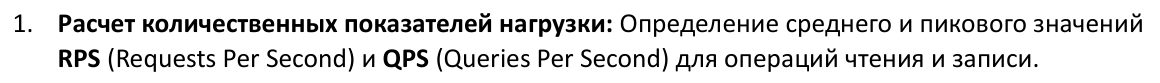

исходные параметры:
- юзеров в сутки: 50 000 000
- публикаций на юзера: 1/7 в сутки (раз в неделю)
- просмотров на юзера: 50 в сутки
- оригинал: 3 мб, с превью: 3.5 мб
- отдаем юзеру: 0.5 мб
- метаданные: 2 кб
- $k_{peak} = 2.5$

публикаций в сутки: $50\,000\,000 \cdot \frac{1}{7} \approx 7\,142\,857$

просмотров в сутки: $50\,000\,000 \cdot 50 = 2\,500\,000\,000$

чтение : запись = $2\,500\,000\,000 : 7\,142\,857 = 350 : 1$

$RPS = \dfrac{\text{запросов в сутки}}{86\,400}$, $\quad RPS_{peak} = RPS \cdot k_{peak}$

запись:
- $RPS_{write} = \dfrac{7\,142\,857}{86\,400} \approx 83$
- $RPS_{write\_peak} = 83 \cdot 2.5 \approx 207$

чтение:
- $RPS_{read} = \dfrac{2\,500\,000\,000}{86\,400} \approx 28\,935$
- $RPS_{read\_peak} = 28\,935 \cdot 2.5 \approx 72\,338$

всего:
- $RPS_{total} = 83 + 28\,935 = 29\,018$
- $RPS_{total\_peak} = 207 + 72\,338 = 72\,545$

запись:
- запросов к БД на одну публикацию: $q = 3$ (сохранить метаданные, добавить пост в ленты подписчиков и тп)
- $QPS_{write} = q \cdot RPS_{write} = 3 \cdot 83 \approx 248$
- $QPS_{write\_peak} = 248 \cdot 2.5 = 620$

чтение — кэш + батчинг:
- размер батча (постов в одной пачке ленты): $b = 20$
- промахи кэша: $cache\_miss = 13\%$
- запросов ленты: $\dfrac{RPS_{read}}{b} = \dfrac{28\,935}{20} \approx 1\,447$
- $QPS_{read} = cache\_miss \cdot \dfrac{RPS_{read}}{b} = 0.13 \cdot 1\,447 \approx 188$
- $QPS_{read\_peak} = 188 \cdot 2.5 = 470$
- отдал кэш: $1\,447 - 188 = 1\,259$, в пике $3\,147$

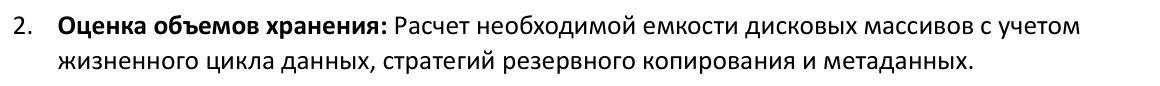

$V_{day} = \text{публикаций в сутки} \cdot \text{размер}$

фото (оригинал + превью):

$V_{day} = 7\,142\,857 \cdot 3.5 \text{ мб} = 25\,000\,000 \text{ мб} = 25 \text{ тб}$

резервирование:
- репликация (3 полные копии): $25 \cdot 3 = 75$ тб/сутки
- erasure coding (файл режется на 8 частей + 4 контрольные): $\frac{8+4}{8} = 1.5$, $\;25 \cdot 1.5 = 37.5$ тб/сутки
- бэкап (еще одна копия в холодное хранилище): ×1

erasure coding + бэкап: $25 \cdot (1.5 + 1) = 62.5$ тб/сутки

метаданные

$V_{meta\_day} = 7\,142\,857 \cdot 2 \text{ кб} \approx 14.3 \text{ гб}$

с индексами (×2) и 2 репликами БД (всего ×3): $14.3 \cdot 2 \cdot 3 \approx 85.7$ гб/сутки

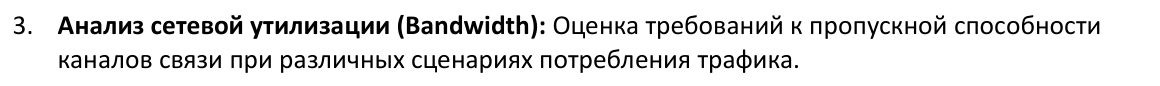

$BW = RPS \cdot \text{размер}$, 1 байт = 8 бит

входящий — юзер грузит оригинал (3 мб):
- $BW_{in} = 83 \cdot 3 = 248 \text{ мб/с} = \dfrac{248 \cdot 8}{1000} \approx 2.0$ гбит/с
- $BW_{in\_peak} = 2.0 \cdot 2.5 = 5.0$ гбит/с

исходящий — отдаем сжатую (0.5 мб):
- $BW_{out} = 28\,935 \cdot 0.5 = 14\,468 \text{ мб/с} = \dfrac{14\,468 \cdot 8}{1000} \approx 115.7$ гбит/с
- $BW_{out\_peak} = 115.7 \cdot 2.5 \approx 289.4$ гбит/с

| сценарий | множитель | RPS чтение | входящий, гбит/с | исходящий, гбит/с |
|---|---|---|---|---|
| обычный день | ×1 | 28 935 | 2.0 | 115.7 |
| час пик (вечер) | ×2.5 | 72 338 | 5.0 | 289.4 |
| праздник | ×4 | 115 741 | 7.9 | 463.0 |

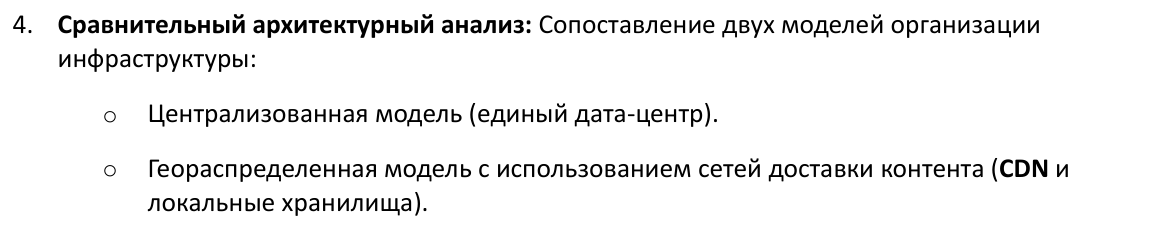

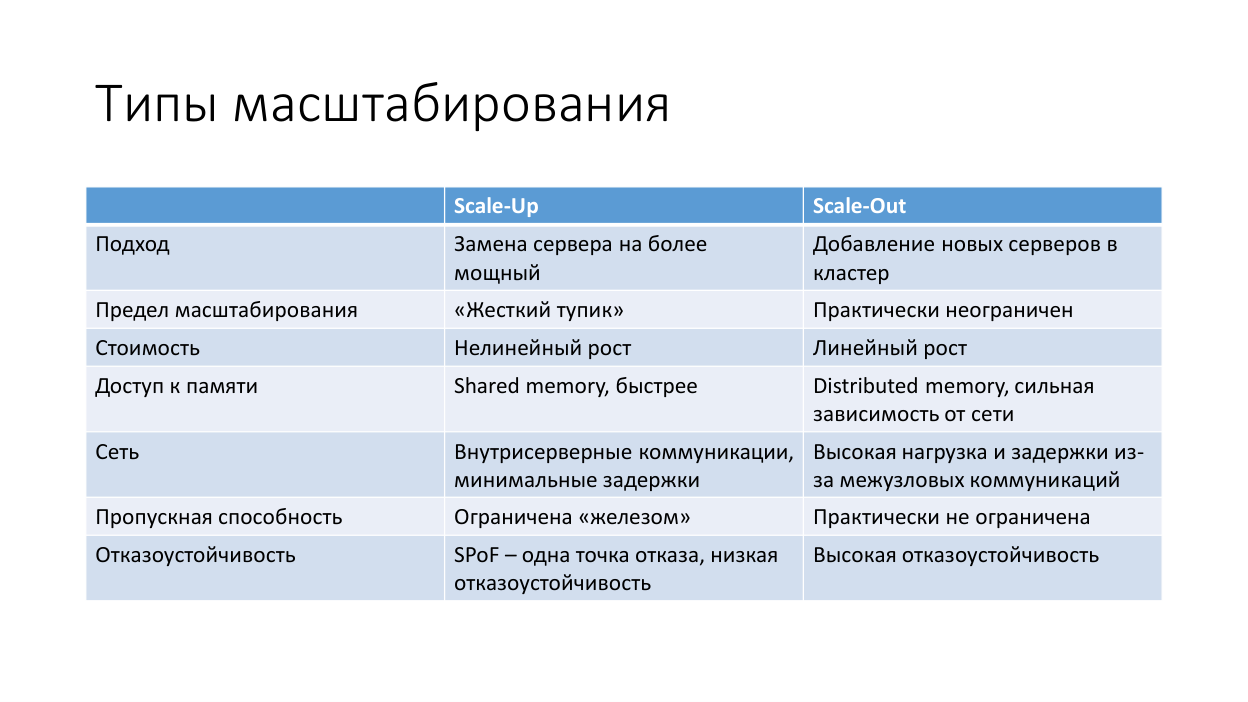

с CDN картинки отдаются с ближайшего к юзеру узла, до основного ДЦ доходят только промахи CDN

CDN отдает 95% картинок:
- 1 ДЦ: исходящий канал в пике $289.4$ гбит/с
- с CDN: $289.4 \cdot (1 - 0.95) \approx 14$ гбит/с

| | централизованная (1 ДЦ) | геораспределенная (CDN + несколько ДЦ) |
|---|---|---|
| масштабирование | Scale-Up | Scale-Out |
| задержка | 150–300 мс для далеких юзеров | 10–30 мс, ближайший узел CDN |
| исходящий канал ДЦ в пике | ~289 гбит/с | ~14 гбит/с |
| отказоустойчивость | SPoF | трафик уходит на соседний |
| предел роста | «жесткий тупик» | практически неограничен |
| стоимость | нелинейный рост | линейный рост |

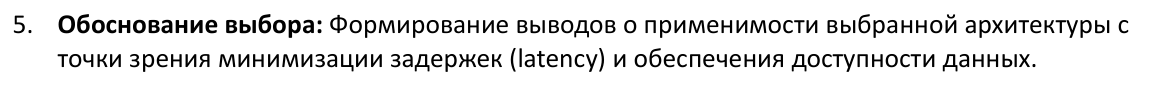

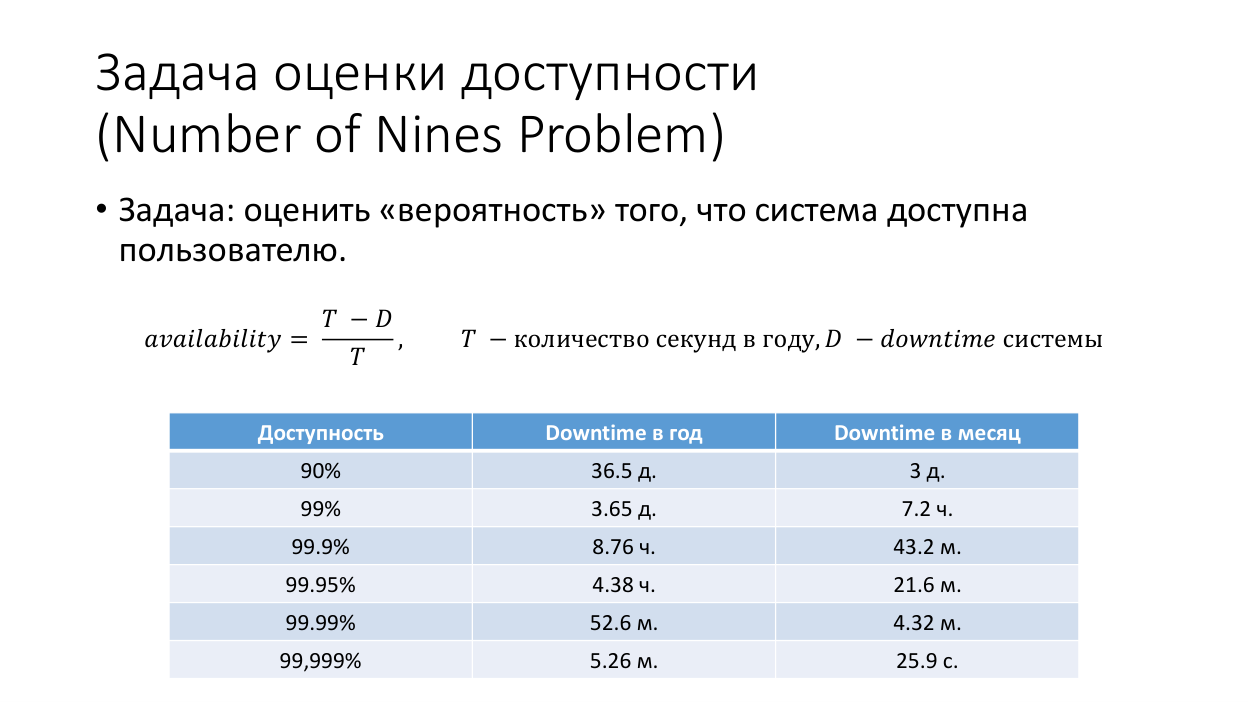

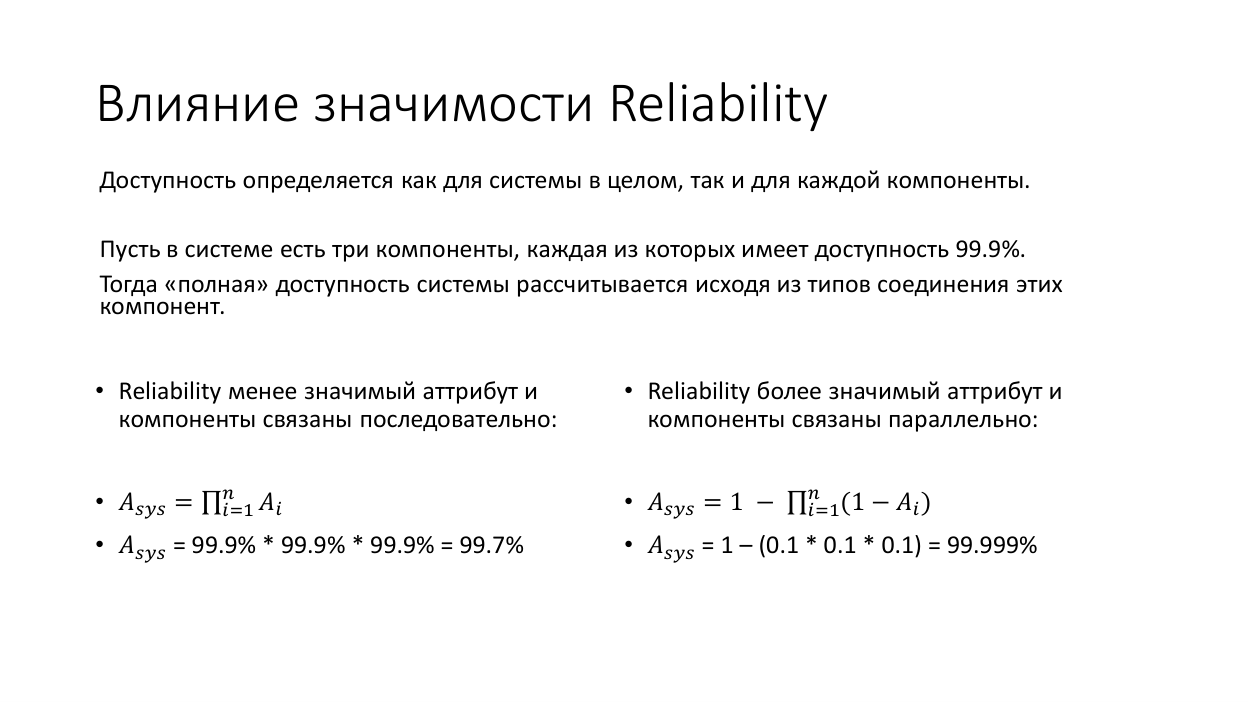

у каждого компонента $A = 99.9\%$

1 ДЦ: провайдер → роутер ДЦ → балансировщик, все последовательно
- $A_{sys} = 0.999 \cdot 0.999 \cdot 0.999 \approx 99.7\%$
- простой: $(1 - 0.997) \cdot 365 \cdot 24 \approx 26.3$ ч/год

3 узла CDN параллельно -> 2 ДЦ параллельно (последовательно)
- $A_{CDN} = 1 - 0.001^3 = 0.999999999$
- $A_{ДЦ} = 1 - 0.001^2 = 0.999999$
- $A_{sys} = A_{CDN} \cdot A_{ДЦ} \approx 99.9999\%$
- простой: $(1 - 0.999999) \cdot 365 \cdot 24 \cdot 60 \approx 0.5$ мин/год

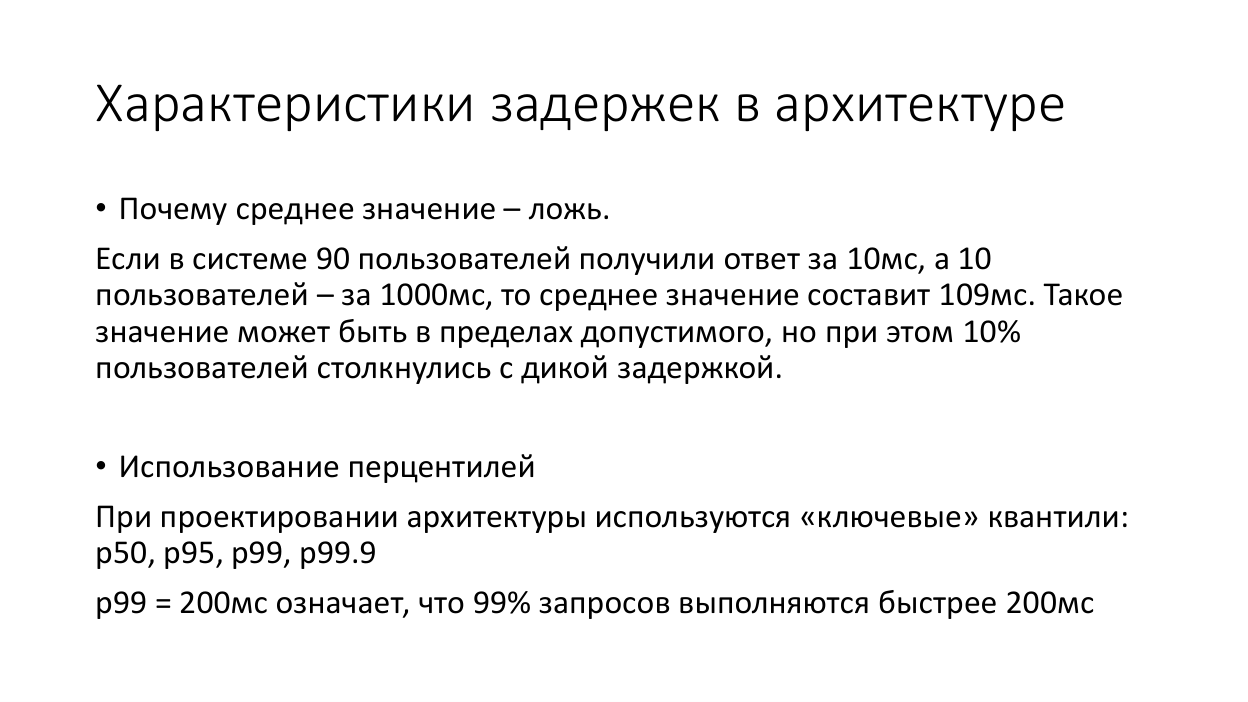

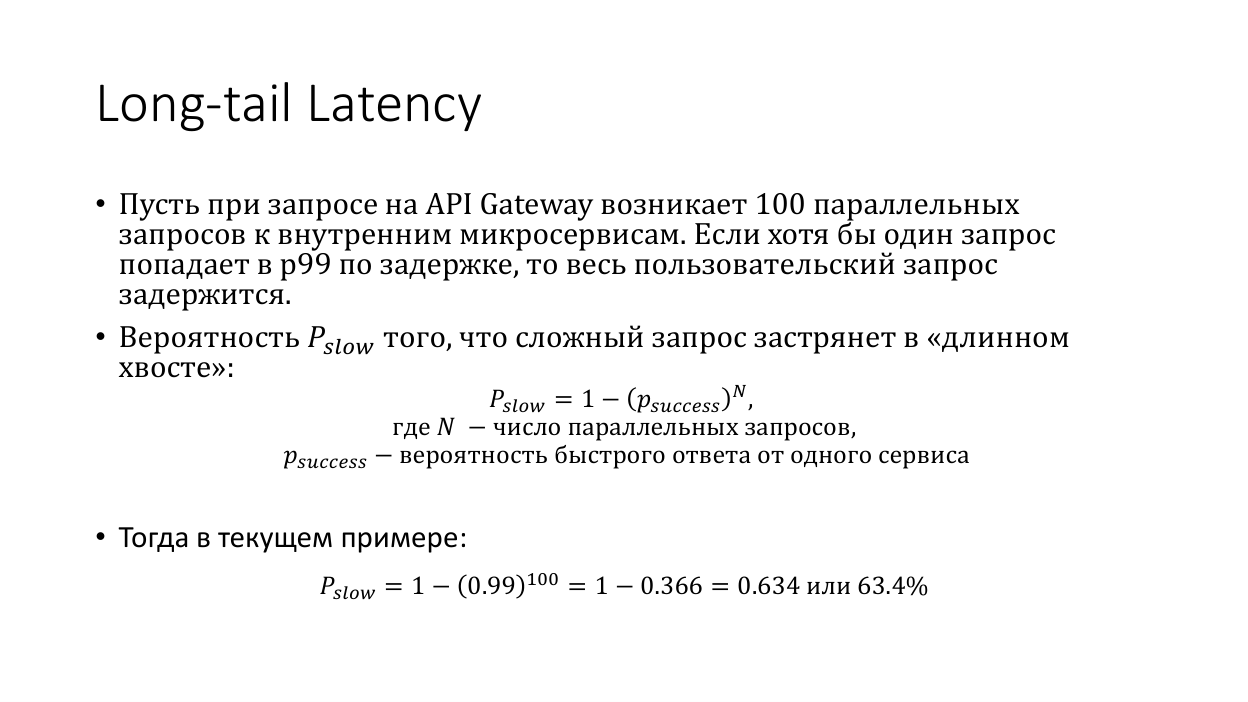

лента = пачка из 20 постов → $N = 20$ параллельных запросов

- 1 ДЦ (далеко, потери пакетов), $p_{success} = 0.98$: $\;P_{slow} = 1 - 0.98^{20} = 1 - 0.668 \approx 33.2\%$
- с CDN, $p_{success} = 0.999$: $\;P_{slow} = 1 - 0.999^{20} = 1 - 0.980 \approx 2.0\%$

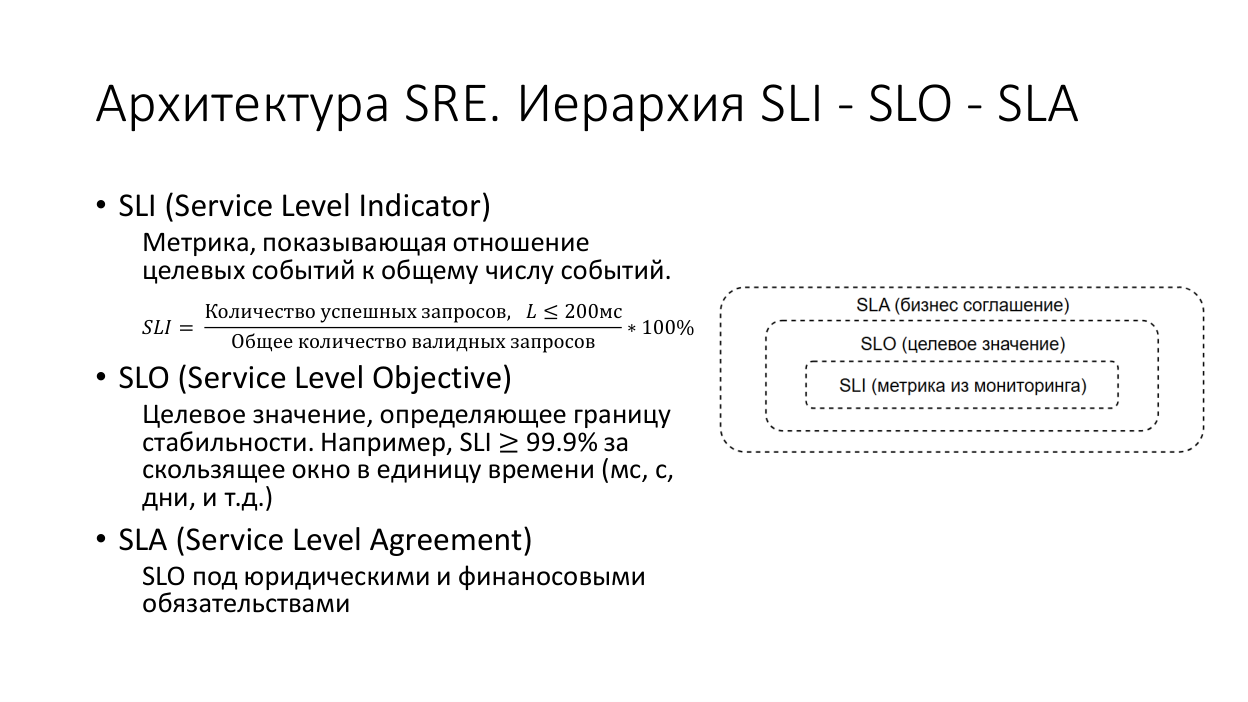

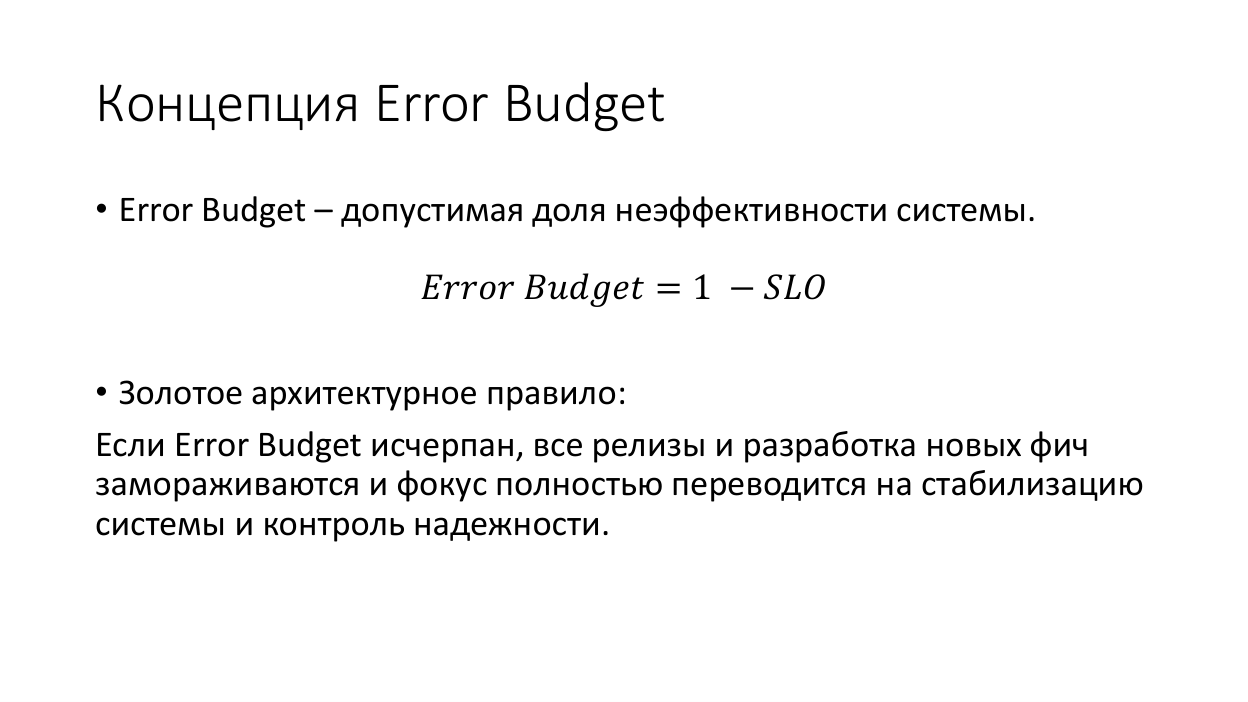

- SLI — доля картинок, отданных за ≤ 200 мс
- SLO — SLI ≥ 99.9% за скользящие 30 дней

$Error\ Budget = 1 - 0.999 = 0.1\%$
- «плохих» запросов в сутки: $2\,500\,000\,000 \cdot 0.001 = 2\,500\,000$
- простоя в месяц: $0.001 \cdot 30 \cdot 24 \cdot 60 = 43.2$ мин

- 1 ДЦ: $99.7\% < 99.9\%$ — SLO не выполнен
- гео + CDN: $99.9999\% \ge 99.9\%$ — SLO выполнен

выбор — геораспределенная модель (CDN + несколько ДЦ):
- доступность 99.7% → 99.9999%
- P_slow 33% → 2%
- исходящий канал ДЦ в пике 289 → 14 гбит/с